# 02 · EDA · De lo macro a lo micro

> **BORRADOR para revisión del grupo.** Cada cifra sale del CSV de entrenamiento (`data/raw/train.csv` o `dataset.csv`) y se calcula en este notebook. Los **insights** son lectura mía
> de esas cifras; lo que dependa del negocio está marcado **[DECIDE EL GRUPO]**. Es un análisis **descriptivo**: muestra asociaciones, no causas.

**Cómo está organizado**
1. **Macro:** qué es el dataset, cómo está el objetivo, qué calidad tiene y si train y test se parecen.
2. **Mapa de variables:** cuánto "sabe" cada variable sobre la respuesta, para saber por dónde empezar.
3. **Micro:** una sección por variable, de la más a la menos informativa, siempre relacionada con `Response`.
4. **Cruces y segmentos:** donde se combinan variables; aquí está el valor para decidir.
5. **Insights y decisiones.**

**Cómo leer los gráficos:** cada barra es la **tasa de aceptación** (porcentaje de clientes con `Response = 1`) de un grupo. La línea gris punteada es el promedio
general (12,26 %). Barras **naranja** = por encima del promedio; **azules** = por debajo. Debajo de cada barra está `n`, el número de clientes del grupo:
una tasa con `n` pequeño no es confiable.

In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mutual_info_score

RAW_DIR = Path.cwd().resolve().parent / "data" / "raw"
ID_COL = "id"
TARGET = "Response"

from proyecto.data.cleaning import find_test_csv, find_train_csv

ROOT = RAW_DIR.parent.parent
TRAIN_PATH = find_train_csv(ROOT)     # data/raw/train.csv, data/raw/dataset.csv o dataset.csv
TEST_PATH = find_test_csv(ROOT)       # opcional: solo existe si se descargó test.csv
train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH) if TEST_PATH else None
df = train.copy()
y = df[TARGET]
BASE = y.mean()
test_info = f"{test.shape[0]:,} x {test.shape[1]}" if test is not None else "no disponible"
print(f"{TRAIN_PATH.name}: {train.shape[0]:,} filas x {train.shape[1]} columnas | test: {test_info}")

# Estilo: colores validados (azul y naranja separan bien también con daltonismo); el naranja lleva siempre el valor escrito
BLUE, ORANGE, GRAY, INK = "#2F6FB5", "#D9822B", "#8A8A8A", "#222222"
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#cccccc",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#eeeeee",
                     "axes.axisbelow": True, "font.size": 10, "axes.titleweight": "bold", "axes.titlesize": 11,
                     "axes.titlelocation": "left", "figure.dpi": 110})

def rate_table(by):
    '''Tasa de aceptación, tamaño y 'lift' (veces el promedio) por grupo.'''
    g = df.groupby(by, observed=True)[TARGET].agg(n="size", compradores="sum", tasa="mean")
    g["lift"] = g["tasa"] / BASE
    g["% de clientes"] = g["n"] / len(df)
    g["% de compradores"] = g["compradores"] / y.sum()
    return g

def rate_bars(g, title, xlabel="", rotate=0, figsize=(8, 3.6)):
    '''Barras de tasa por grupo, con la tasa escrita y el n debajo.'''
    fig, ax = plt.subplots(figsize=figsize)
    x = np.arange(len(g))
    colors = [ORANGE if t > BASE else BLUE for t in g["tasa"]]
    ax.bar(x, g["tasa"] * 100, color=colors, width=0.7)
    ax.axhline(BASE * 100, color=GRAY, ls="--", lw=1, label=f"promedio general {BASE:.1%}")
    ax.legend(loc="lower right", bbox_to_anchor=(1, 1.0), frameon=False, fontsize=8)
    for xi, (t, n) in enumerate(zip(g["tasa"], g["n"])):
        ax.text(xi, t * 100 + 0.4, f"{t:.1%}", ha="center", va="bottom", fontsize=8.5, color=INK)
    ax.set_xticks(x)
    ax.set_xticklabels([f"{str(i)}\nn={n:,}" for i, n in zip(g.index, g["n"])], rotation=rotate, fontsize=8)
    ax.set_ylabel("Tasa de aceptación (%)")
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    ax.set_ylim(0, max(g["tasa"].max() * 100 * 1.18, BASE * 100 * 1.4))
    plt.tight_layout()
    plt.show()

def show(g):
    out = g.copy()
    for c in ["tasa", "% de clientes", "% de compradores"]:
        out[c] = (out[c] * 100).round(1).astype(str) + " %"
    out["lift"] = out["lift"].round(2)
    display(out[["n", "compradores", "tasa", "lift", "% de clientes", "% de compradores"]])

train.csv: 381,109 filas x 12 columnas | test: 127,037 x 11


## 1. Macro · ¿Qué es el dataset?

In [2]:
print(f"Filas x columnas (train): {df.shape[0]:,} x {df.shape[1]}")
print(f"Un cliente por fila: id único = {df[ID_COL].is_unique}; filas duplicadas = {df.duplicated().sum()}")
print(f"Nulos en total: {df.isna().sum().sum()}")
if test is not None:
    print(f"Rango de id: train {train.id.min():,} a {train.id.max():,}; test {test.id.min():,} a {test.id.max():,}")
    print(f"'Response' en test: {'Response' in test.columns}  (test no sirve para evaluar, solo para predecir)")
else:
    print(f"Rango de id (train): {train.id.min():,} a {train.id.max():,}. No hay test.csv: se omite lo que dependa de él.")
display(pd.DataFrame({"tipo": df.dtypes.astype(str), "valores distintos": df.nunique(), "ejemplo": df.iloc[0]}))

Filas x columnas (train): 381,109 x 12


Un cliente por fila: id único = True; filas duplicadas = 0
Nulos en total: 0
Rango de id: train 1 a 381,109; test 381,110 a 508,146
'Response' en test: False  (test no sirve para evaluar, solo para predecir)


,tipo,valores distintos,ejemplo
id,int64,381109,1
Gender,str,2,Male
Age,int64,66,44
Driving_License,int64,2,1
Region_Code,float64,53,28.0
Previously_Insured,int64,2,0
Vehicle_Age,str,3,> 2 Years
Vehicle_Damage,str,2,Yes
Annual_Premium,float64,48838,40454.0
Policy_Sales_Channel,float64,155,26.0


**Lectura:** cada fila es un **cliente distinto** (`id` único, sin duplicados ni nulos). Por eso la partición entrenamiento/validación/prueba puede hacerse **por fila**,
estratificada por `Response`, sin riesgo de que un mismo cliente aparezca en dos conjuntos. El `id` solo identifica: **no es una variable para predecir**.
`test.csv` no trae la respuesta, así que los modelos se evalúan partiendo `train.csv`.

### 1.1 El objetivo

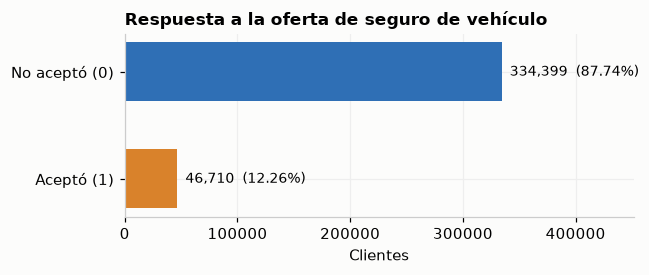

Por cada comprador hay 7.2 que no compran.
Línea base: 'siempre no' acierta 87.74% y no encuentra a ningún comprador.


In [3]:
counts = y.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 2.6))
ax.barh(["Aceptó (1)", "No aceptó (0)"], [counts[1], counts[0]], color=[ORANGE, BLUE], height=0.55)
for i, v in enumerate([counts[1], counts[0]]):
    ax.text(v, i, f"  {v:,}  ({v / len(df):.2%})", va="center", fontsize=9)
ax.set_xlim(0, counts.max() * 1.35)
ax.set_title("Respuesta a la oferta de seguro de vehículo")
ax.set_xlabel("Clientes")
plt.tight_layout()
plt.show()
print(f"Por cada comprador hay {counts[0] / counts[1]:.1f} que no compran.")
print(f"Línea base: 'siempre no' acierta {counts[0] / len(df):.2%} y no encuentra a ningún comprador.")

**Insight 1 · El comprador es la excepción (1 de cada 8).** Por eso (a) la exactitud engaña, (b) hay que partir **estratificando** por `Response` y (c) se evalúa con
PR-AUC y con costo (ver `01_caso_negocio.ipynb`). **Decisión de negocio:** no se puede llamar a todos esperando buenos resultados; hay que **priorizar**.

### 1.2 Calidad y parecido entre train y test

_Si el repositorio no tiene `test.csv`, la comparación se omite y solo se revisa la prima._

In [4]:
num = ["Age", "Annual_Premium", "Vintage"]
if test is None:
    print("No hay test.csv en este repositorio: se omite la comparación entre train y test.")
else:
    cmp_ = pd.DataFrame({"train (media)": train[num].mean(), "test (media)": test[num].mean(),
                         "train (mediana)": train[num].median(), "test (mediana)": test[num].median()}).round(1)
    display(cmp_)

    print("Proporciones de variables categóricas, train vs test (puntos porcentuales de diferencia):")
    rows = []
    for c in ["Gender", "Vehicle_Age", "Vehicle_Damage", "Previously_Insured", "Driving_License"]:
        a = train[c].value_counts(normalize=True)
        b = test[c].value_counts(normalize=True)
        for k in a.index:
            rows.append({"variable": c, "valor": k, "train": a[k], "test": b.get(k, 0), "diferencia (pp)": (b.get(k, 0) - a[k]) * 100})
    display(pd.DataFrame(rows).round(3).set_index(["variable", "valor"]))

    unseen_ch = sorted(set(test.Policy_Sales_Channel) - set(train.Policy_Sales_Channel))
    unseen_rg = sorted(set(test.Region_Code) - set(train.Region_Code))
    print(f"Canales de venta que están en test y no en train: {unseen_ch}; regiones: {unseen_rg}")
print(f"Prima: {(df.Annual_Premium == df.Annual_Premium.min()).mean():.1%} de las filas vale exactamente el mínimo ({df.Annual_Premium.min():,.0f}); "
      f"máximo {df.Annual_Premium.max():,.0f} vs percentil 99 {df.Annual_Premium.quantile(.99):,.0f}.")

,train (media),test (media),train (mediana),test (mediana)
Age,38.8,38.8,36.0,36.0
Annual_Premium,30564.4,30524.6,31669.0,31642.0
Vintage,154.3,154.3,154.0,154.0


Proporciones de variables categóricas, train vs test (puntos porcentuales de diferencia):


train   test  diferencia (pp)
variable           valor                                   
Gender             Male       0.541  0.537           -0.363
                   Female     0.459  0.463            0.363
Vehicle_Age        1-2 Year   0.526  0.525           -0.058
                   < 1 Year   0.432  0.433            0.071
                   > 2 Years  0.042  0.042           -0.013
Vehicle_Damage     Yes        0.505  0.502           -0.239
                   No         0.495  0.498            0.239
Previously_Insured 0          0.542  0.540           -0.183
                   1          0.458  0.460            0.183
Driving_License    1          0.998  0.998            0.027
                   0          0.002  0.002           -0.027

Canales de venta que están en test y no en train: [141.0, 142.0]; regiones: []
Prima: 17.0% de las filas vale exactamente el mínimo (2,630); máximo 540,165 vs percentil 99 72,963.


**Insight 2 · Los datos están limpios y train y test se parecen.** Sin nulos, sin duplicados, medias y proporciones casi idénticas. Lo que se aprenda en train debería
aplicarse a test. Las únicas sorpresas: **canales de venta que aparecen solo en test** (hay que decidir qué hacer con un canal desconocido, por ejemplo agruparlo en
"otros") y la **prima** con un mínimo repetido en el 17 % de las filas.

## 2. Mapa · ¿Qué variables "saben" más sobre la respuesta?

Se usa la **información mutua**: mide cuánto se reduce la incertidumbre sobre `Response` al conocer la variable (0 % = no dice nada; 100 % = lo dice todo).
Las variables numéricas se agrupan en 10 tramos de igual tamaño. En el gráfico, **naranja** = las que explican más del 5 %. Es una medida descriptiva que sirve para ordenar el trabajo, no un modelo.

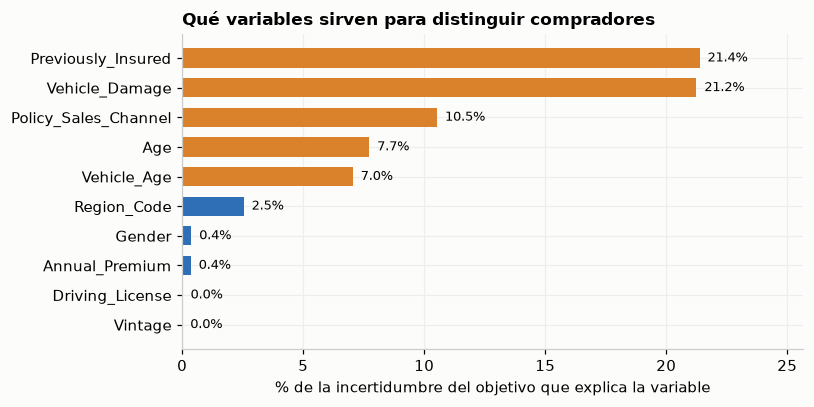

In [5]:
H = -(BASE * np.log(BASE) + (1 - BASE) * np.log(1 - BASE))
cols = {"Previously_Insured": df.Previously_Insured, "Vehicle_Damage": df.Vehicle_Damage, "Vehicle_Age": df.Vehicle_Age,
        "Policy_Sales_Channel": df.Policy_Sales_Channel, "Region_Code": df.Region_Code, "Gender": df.Gender,
        "Driving_License": df.Driving_License,
        "Age": pd.qcut(df.Age, 10, duplicates="drop"), "Annual_Premium": pd.qcut(df.Annual_Premium, 10, duplicates="drop"),
        "Vintage": pd.qcut(df.Vintage, 10, duplicates="drop")}
mi = pd.Series({k: mutual_info_score(v.astype(str), y) / H for k, v in cols.items()}).sort_values()

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.barh(mi.index, mi * 100, color=[ORANGE if v > 0.05 else BLUE for v in mi], height=0.65)
for i, v in enumerate(mi):
    ax.text(v * 100, i, f"  {v:.1%}", va="center", fontsize=8.5)
ax.set_xlim(0, mi.max() * 100 * 1.2)
ax.set_xlabel("% de la incertidumbre del objetivo que explica la variable")
ax.set_title("Qué variables sirven para distinguir compradores")
plt.tight_layout()
plt.show()

**Insight 3 · Dos variables concentran casi todo: `Previously_Insured` y `Vehicle_Damage` (≈ 21 % cada una).** Después vienen el canal de venta (≈ 10,5 %), la edad (≈ 7,7 %) y la antigüedad
del vehículo (≈ 7 %). Región aporta poco (≈ 2,5 %) y **género, prima, licencia y antigüedad como cliente (`Vintage`) prácticamente nada (0,4 % o menos)**.
El resto de este notebook sigue ese orden.

## 3. Micro · Variable por variable frente a la respuesta

### 3.1 `Previously_Insured` · ¿ya tiene seguro de vehículo?

,n,compradores,tasa,lift,% de clientes,% de compradores
Previously_Insured,,,,,,
No tiene seguro (0),206481,46552,22.5 %,1.84,54.2 %,99.7 %
Ya tiene seguro (1),174628,158,0.1 %,0.01,45.8 %,0.3 %


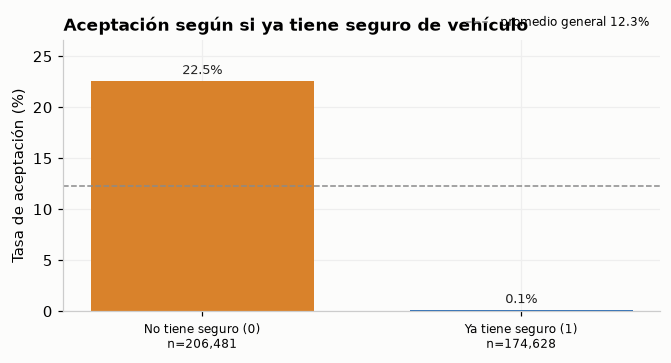

In [6]:
g = rate_table("Previously_Insured")
g.index = g.index.map({0: "No tiene seguro (0)", 1: "Ya tiene seguro (1)"})
show(g)
rate_bars(g, "Aceptación según si ya tiene seguro de vehículo", figsize=(6.2, 3.4))

**Insight 4 · Quien ya tiene seguro de vehículo casi nunca compra otro (0,1 % frente a 22,5 %).** El 46 % de los clientes ya está asegurado y aporta una fracción mínima de los compradores.
**Decisión de negocio:** excluir de la lista de llamadas a quien ya tiene seguro ahorra casi la mitad de los contactos prácticamente sin perder ventas.
Es una señal lógica (nadie contrata dos seguros de vehículo), no una fuga.

### 3.2 `Vehicle_Damage` · ¿el vehículo tuvo daños?

,n,compradores,tasa,lift,% de clientes,% de compradores
Vehicle_Damage,,,,,,
No,188696,982,0.5 %,0.04,49.5 %,2.1 %
Yes,192413,45728,23.8 %,1.94,50.5 %,97.9 %


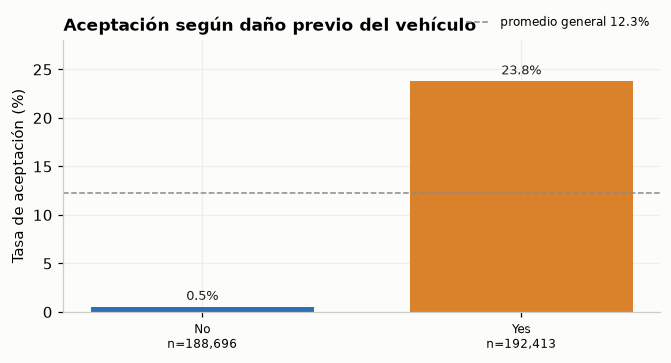

In [7]:
g = rate_table("Vehicle_Damage")
show(g)
rate_bars(g, "Aceptación según daño previo del vehículo", figsize=(6.2, 3.4))

**Insight 5 · Quien tuvo un daño acepta unas 46 veces más (23,8 % frente a 0,5 %).** Quienes no han tenido daños casi no compran. Una explicación plausible: el daño hace sentir
la necesidad del seguro **[DECIDE EL GRUPO: validar con el negocio; esto es una hipótesis]**. Por sí sola esta variable concentra casi todos los compradores,
pero está muy ligada a `Previously_Insured`, así que su valor real se ve en el cruce de la sección 4.

### 3.3 `Policy_Sales_Channel` · canal de venta (155 valores)

Canales con 1.000 filas o más: 21 de 155; cubren 95.9% de los clientes.
Canales con menos de 100 filas: 92 (su tasa no es confiable).


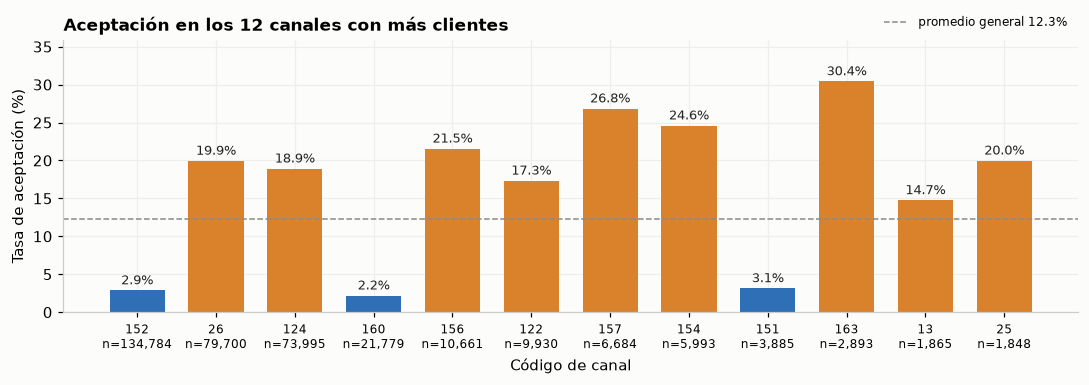

,clientes,tasa,edad_mediana,pct_con_daño,pct_ya_asegurado
Policy_Sales_Channel,,,,,
152.0,134784,0.029,25.0,0.226,0.730
26.0,79700,0.199,49.0,0.674,0.303
124.0,73995,0.189,45.0,0.679,0.285
160.0,21779,0.022,21.0,0.439,0.536
156.0,10661,0.215,37.0,0.839,0.131
122.0,9930,0.173,50.0,0.697,0.260


Dentro del segmento clave (no asegurado y con daño), tasa por canal:


,clientes,tasa
Policy_Sales_Channel,,
152.0,28156,0.127
26.0,51284,0.307
124.0,48551,0.284
160.0,8342,0.051
156.0,8358,0.261
122.0,6789,0.250


In [8]:
ch = rate_table("Policy_Sales_Channel").sort_values("n", ascending=False)
print(f"Canales con 1.000 filas o más: {(ch.n >= 1000).sum()} de {len(ch)}; cubren {ch[ch.n >= 1000].n.sum() / len(df):.1%} de los clientes.")
print(f"Canales con menos de 100 filas: {(ch.n < 100).sum()} (su tasa no es confiable).")
top = ch.head(12).copy()
top.index = top.index.astype(int)
rate_bars(top, "Aceptación en los 12 canales con más clientes", xlabel="Código de canal", figsize=(10, 3.6))

# ¿El canal es un efecto propio o solo refleja a qué clientes atiende?
prof = df.assign(dmg=(df.Vehicle_Damage == "Yes")).groupby("Policy_Sales_Channel").agg(
    clientes=("id", "size"), tasa=("Response", "mean"), edad_mediana=("Age", "median"),
    pct_con_daño=("dmg", "mean"), pct_ya_asegurado=("Previously_Insured", "mean")).sort_values("clientes", ascending=False).head(6)
display(prof.round(3))

key = df[(df.Previously_Insured == 0) & (df.Vehicle_Damage == "Yes")]
inseg = key.groupby("Policy_Sales_Channel").Response.agg(clientes="size", tasa="mean").loc[[152, 26, 124, 160, 156, 122]]
print("Dentro del segmento clave (no asegurado y con daño), tasa por canal:")
display(inseg.round(3))

**Insight 6 · El canal separa muy bien: los canales 152 y 160 rinden 2-3 %, y los 26, 124 y 156 rinden 19-22 %.** Pero **en buena parte es porque atienden a clientes distintos**: el canal 152 vende a
clientes de 25 años de mediana, 73 % ya asegurados y 23 % con daño; el 26 vende a clientes de 49 años, 30 % ya asegurados y 67 % con daño. Aun así, **dentro del mismo segmento
clave (no asegurado y con daño) los canales 152 y 160 siguen rindiendo menos (12,7 % y 5,1 %)** que el 26 o el 124 (≈ 28-31 %). Queda un efecto propio del canal.
**Decisión de negocio:** revisar qué se ofrece y cómo en los canales 152 y 160, que mueven 41 % de los clientes con una conversión muy baja. **Decisión de datos:**
tratar el canal como categórica y agrupar los de pocos clientes en "otros" **[DECIDE EL GRUPO: umbral de agrupación]**.

### 3.4 `Age` · edad

,n,compradores,tasa,lift,% de clientes,% de compradores
Age_tramo,,,,,,
20-25,114505,4047,3.5 %,0.29,30.0 %,8.7 %
26-35,72307,8198,11.3 %,0.93,19.0 %,17.6 %
36-45,70532,15192,21.5 %,1.76,18.5 %,32.5 %
46-55,61549,12123,19.7 %,1.61,16.1 %,26.0 %
56-65,34147,4815,14.1 %,1.15,9.0 %,10.3 %
66+,28069,2335,8.3 %,0.68,7.4 %,5.0 %


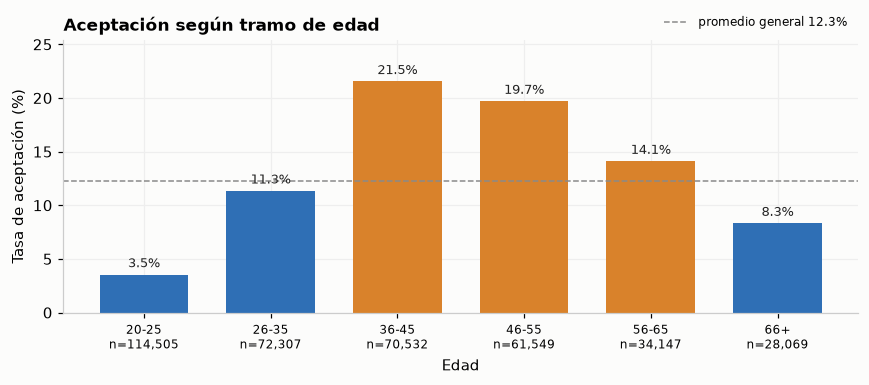

In [9]:
df["Age_tramo"] = pd.cut(df.Age, [19, 25, 35, 45, 55, 65, 90], labels=["20-25", "26-35", "36-45", "46-55", "56-65", "66+"])
g = rate_table("Age_tramo")
show(g)
rate_bars(g, "Aceptación según tramo de edad", xlabel="Edad", figsize=(8, 3.6))

**Insight 7 · La edad dibuja una "campana": sube hasta los 36-45 años (21,5 %) y baja después (8,3 % a partir de los 66).** Los menores de 26 casi no compran (3,5 %) y son 30 % de los clientes.
Una relación recta con la edad no representa esto. **Decisión de datos:** usar modelos que capturen relaciones no lineales o tramos de edad. **Decisión de negocio:** el núcleo comercial está entre 26 y 55 años.

### 3.5 `Vehicle_Age` · antigüedad del vehículo

,n,compradores,tasa,lift,% de clientes,% de compradores
Vehicle_Age,,,,,,
< 1 Year,164786,7202,4.4 %,0.36,43.2 %,15.4 %
1-2 Year,200316,34806,17.4 %,1.42,52.6 %,74.5 %
> 2 Years,16007,4702,29.4 %,2.40,4.2 %,10.1 %


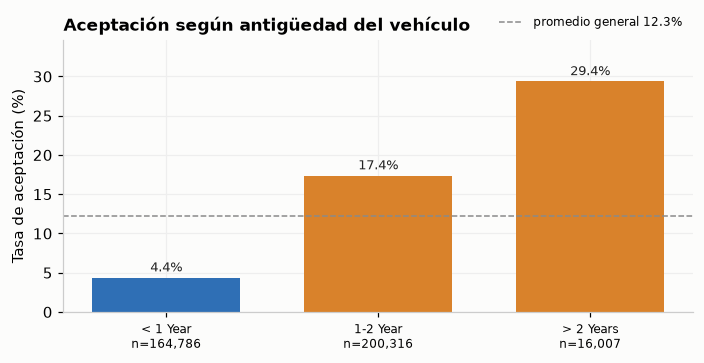

In [10]:
g = rate_table("Vehicle_Age").loc[["< 1 Year", "1-2 Year", "> 2 Years"]]
show(g)
rate_bars(g, "Aceptación según antigüedad del vehículo", figsize=(6.5, 3.4))

**Insight 8 · A mayor antigüedad del vehículo, mayor aceptación (4,4 % → 17,4 % → 29,4 %).** Pero los de más de 2 años son solo 4 % de los clientes; el grueso está en menos de 1 año y entre 1 y 2.
La antigüedad tiene orden natural (0-1-2), así que se puede codificar como número ordenado. Su efecto se mezcla con el daño: ver sección 4.

### 3.6 `Region_Code` · región (53 valores)

Región 28: 106,415 clientes (27.9% del total), tasa 18.7%.
Rango de tasas entre regiones: 4.1% a 19.2%; la región con menos clientes tiene 183.


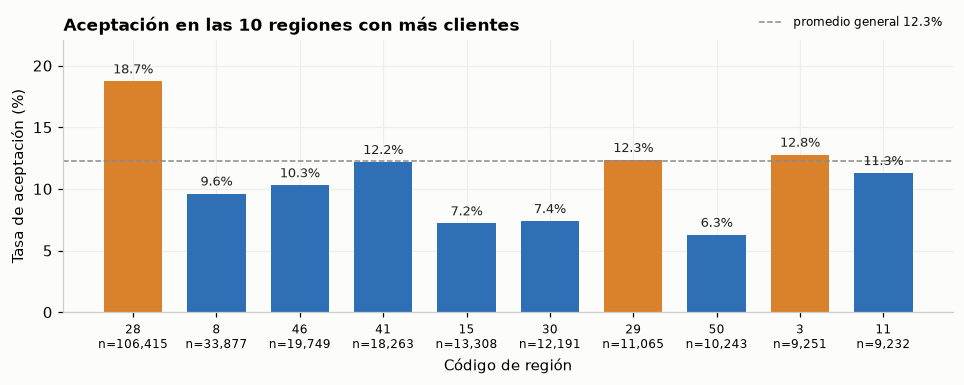

Regiones con menor y mayor tasa (con al menos 1.000 clientes):


,n,tasa,lift
Region_Code,,,
25.0,2503,0.043,0.349
10.0,4374,0.060,0.491
50.0,10243,0.063,0.511
19.0,1535,0.163,1.329
28.0,106415,0.187,1.527
38.0,2026,0.192,1.567


In [11]:
rg = rate_table("Region_Code").sort_values("n", ascending=False)
print(f"Región 28: {rg.loc[28, 'n']:,.0f} clientes ({rg.loc[28, '% de clientes']:.1%} del total), tasa {rg.loc[28, 'tasa']:.1%}.")
print(f"Rango de tasas entre regiones: {rg.tasa.min():.1%} a {rg.tasa.max():.1%}; la región con menos clientes tiene {rg.n.min():,.0f}.")
top = rg.head(10).copy()
top.index = top.index.astype(int)
rate_bars(top, "Aceptación en las 10 regiones con más clientes", xlabel="Código de región", figsize=(9, 3.6))
print("Regiones con menor y mayor tasa (con al menos 1.000 clientes):")
big = rg[rg.n >= 1000].sort_values("tasa")
display(pd.concat([big.head(3), big.tail(3)])[["n", "tasa", "lift"]].round(3))

**Insight 9 · La región 28 concentra 28 % de los clientes y rinde 18,7 %, mejor que el promedio (12,3 %).** Entre las regiones con más de 1.000 clientes, la 25, la 10 y la 50 rinden solo 4-6 %. El rango entre regiones es amplio (4 % a 19 %),
pero la variable aporta poco en total (≈ 2,5 %) porque la mayoría está en pocas regiones. **Decisión de datos:** tratarla como categórica (los números son códigos, sin orden).
**Decisión de negocio:** la región 28 es el mercado central; las regiones con tasa baja (por ejemplo 10, 25 y 50) quizá no justifiquen campañas.

### 3.7 `Gender` · género

,n,compradores,tasa,lift,% de clientes,% de compradores
Gender,,,,,,
Female,175020,18185,10.4 %,0.85,45.9 %,38.9 %
Male,206089,28525,13.8 %,1.13,54.1 %,61.1 %


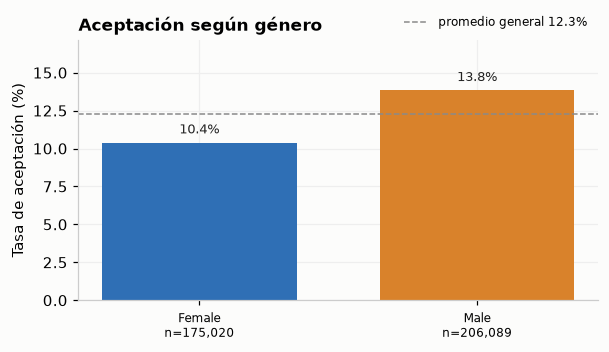

Dentro del segmento clave (no asegurado y con daño): {'Female': 0.234, 'Male': 0.261}


In [12]:
g = rate_table("Gender")
show(g)
rate_bars(g, "Aceptación según género", figsize=(5.5, 3.3))
key = df[(df.Previously_Insured == 0) & (df.Vehicle_Damage == "Yes")]
print("Dentro del segmento clave (no asegurado y con daño):", key.groupby("Gender").Response.mean().round(3).to_dict())

**Insight 10 · Los hombres aceptan algo más (13,8 % frente a 10,4 %), pero casi toda la diferencia desaparece al comparar clientes parecidos** (23,4 % mujeres y 26,1 % hombres dentro del segmento clave).
Aporta menos de 0,4 % de información. **Decisión de datos y ética:** no es una variable que convenga usar para decidir a quién llamar; si se incluye, hay que revisar que el modelo no deje de ofrecer el producto a mujeres.

### 3.8 `Annual_Premium` · prima anual

,n,compradores,tasa,lift,% de clientes,% de compradores
hasta 22k,76222,9451,12.4 %,1.01,20.0 %,20.2 %
hasta 26k,38120,3680,9.7 %,0.79,10.0 %,7.9 %
hasta 29k,38116,3874,10.2 %,0.83,10.0 %,8.3 %
hasta 32k,38111,4201,11.0 %,0.90,10.0 %,9.0 %
hasta 34k,38103,4343,11.4 %,0.93,10.0 %,9.3 %
hasta 38k,38111,4734,12.4 %,1.01,10.0 %,10.1 %
hasta 42k,38106,5154,13.5 %,1.10,10.0 %,11.0 %
hasta 48k,38111,5486,14.4 %,1.17,10.0 %,11.7 %
hasta 540k,38109,5787,15.2 %,1.24,10.0 %,12.4 %


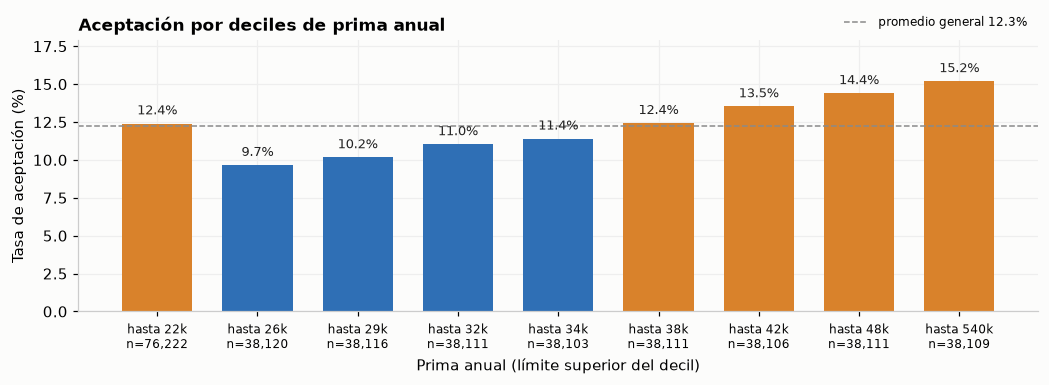

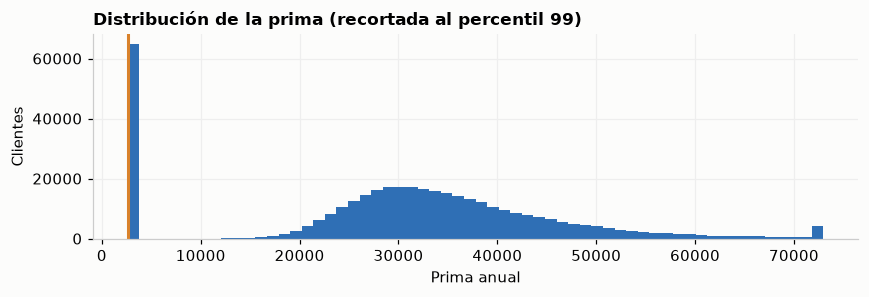

In [13]:
df["Prima_decil"] = pd.qcut(df.Annual_Premium, 10, duplicates="drop")
g = rate_table("Prima_decil")
g.index = [f"hasta {iv.right / 1000:.0f}k" for iv in g.index]
show(g)
rate_bars(g, "Aceptación por deciles de prima anual", xlabel="Prima anual (límite superior del decil)", rotate=0, figsize=(9.5, 3.6))

fig, ax = plt.subplots(figsize=(8, 2.8))
ax.hist(df.Annual_Premium.clip(upper=df.Annual_Premium.quantile(.99)), bins=60, color=BLUE)
ax.axvline(df.Annual_Premium.min(), color=ORANGE, lw=2)
ax.set_title("Distribución de la prima (recortada al percentil 99)")
ax.set_xlabel("Prima anual")
ax.set_ylabel("Clientes")
plt.tight_layout()
plt.show()

**Insight 11 · La prima casi no distingue compradores (aporta ≈ 0,35 %).** La tasa sube de forma suave, de 9,7 % a 15,2 % entre el decil más bajo y el más alto, una diferencia pequeña frente a las variables anteriores. El pico a la izquierda es el **valor mínimo repetido (2.630) en el 17 % de las filas**, y el máximo (540.165) está muy lejos
del percentil 99 (72.963). **Decisión de datos:** señalar el mínimo con un indicador y limitar o transformar los extremos para que no distorsionen a los modelos lineales.
**Decisión de negocio:** no basar la segmentación en el monto de la prima.

### 3.9 `Driving_License` y 3.10 `Vintage`

,n,compradores,tasa,lift,% de clientes,% de compradores
Driving_License,,,,,,
0,812,41,5.0 %,0.41,0.2 %,0.1 %
1,380297,46669,12.3 %,1.00,99.8 %,99.9 %


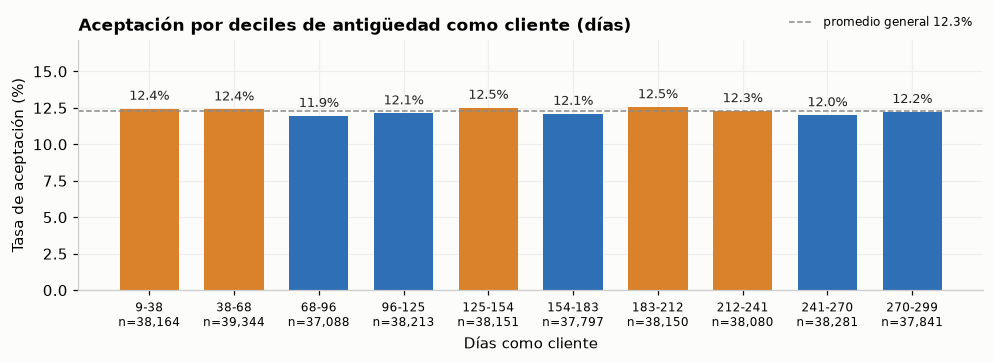

Correlación de Vintage con la respuesta: -0.0011


In [14]:
g = rate_table("Driving_License")
show(g)
df["Vintage_decil"] = pd.qcut(df.Vintage, 10)
g2 = rate_table("Vintage_decil")
g2.index = [f"{int(iv.left)}-{int(iv.right)}" for iv in g2.index]
rate_bars(g2, "Aceptación por deciles de antigüedad como cliente (días)", xlabel="Días como cliente", figsize=(9, 3.4))
print(f"Correlación de Vintage con la respuesta: {df['Vintage'].corr(df[TARGET]):.4f}")

**Insight 12 · `Driving_License` y `Vintage` no ayudan.** Casi todos tienen licencia (99,8 %), así que la variable es casi constante; los 812 sin licencia aceptan 5,0 %. `Vintage` rinde ≈ 12 % en todos sus tramos
y su correlación con la respuesta es -0,001: **parece ruido**. **Decisión de datos:** conservarlas en una primera versión y medir el modelo **con y sin** `Vintage` en la etapa 4; si no aporta, descartarla.

## 4. Cruces y segmentos · donde se decide

Una variable sola cuenta una parte de la historia. Aquí se combinan las dos más fuertes.

,n,compradores,tasa,lift,% de clientes,% de compradores
Sin seguro · con daño,182491,45642,25.0 %,2.04,47.9 %,97.7 %
Sin seguro · sin daño,23990,910,3.8 %,0.31,6.3 %,1.9 %
Ya asegurado · con daño,9922,86,0.9 %,0.07,2.6 %,0.2 %
Ya asegurado · sin daño,164706,72,0.0 %,0.00,43.2 %,0.2 %


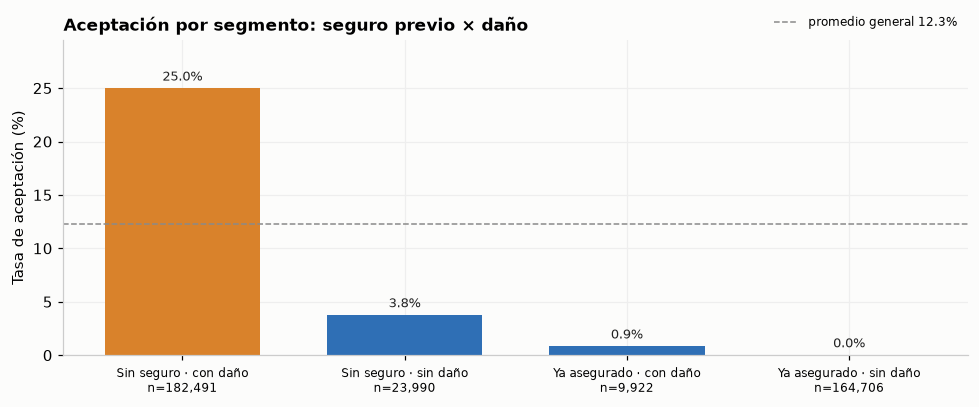

In [15]:
seg = rate_table(["Previously_Insured", "Vehicle_Damage"])
seg.index = [f"{'Ya asegurado' if a else 'Sin seguro'} · {'con daño' if b == 'Yes' else 'sin daño'}" for a, b in seg.index]
seg = seg.sort_values("tasa", ascending=False)
show(seg)
rate_bars(seg, "Aceptación por segmento: seguro previo × daño", figsize=(9, 3.8))

**Insight 13 · Un solo segmento contiene casi todo: "sin seguro y con daño" reúne 48 % de los clientes y 97,7 % de los compradores, con una tasa de 25 %.** Los otros tres segmentos suman 52 % de los clientes y solo 2,3 % de los compradores
(tasas de 3,8 %, 0,9 % y 0,04 %). **Decisión de negocio:** la regla simple "llamar solo a quien no tiene seguro y tuvo daño" ya descarta más de la mitad de las llamadas perdiendo muy pocas ventas.
Es la referencia que el modelo debe superar. **Cuidado:** que 25 % siga siendo bajo significa que dentro del segmento clave **3 de cada 4 llamadas aún no vende**, y ahí es donde el modelo puede aportar.

Dentro del segmento clave: 182,491 clientes, tasa 25.0%


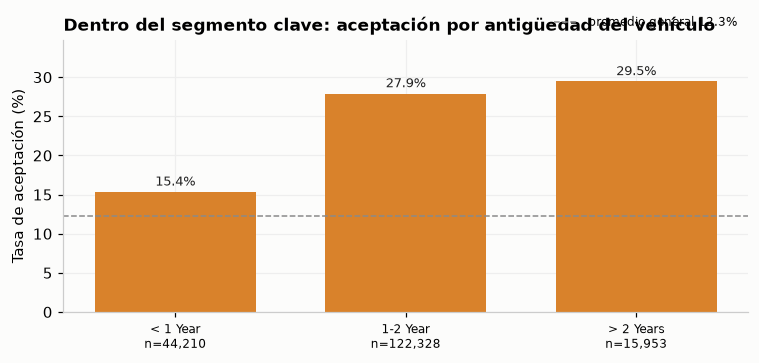

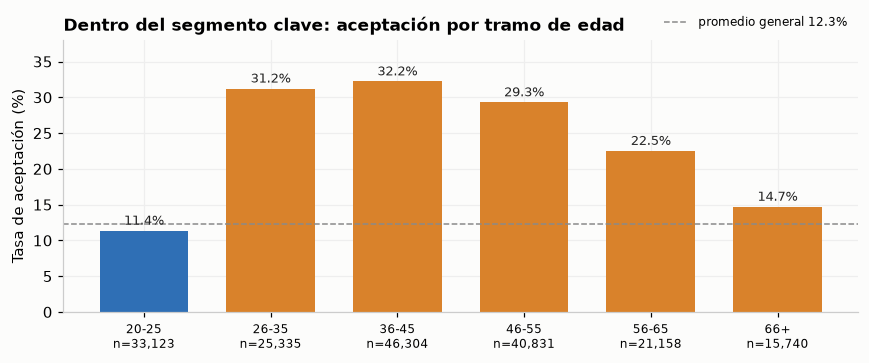

In [16]:
key = df[(df.Previously_Insured == 0) & (df.Vehicle_Damage == "Yes")]
print(f"Dentro del segmento clave: {len(key):,} clientes, tasa {key.Response.mean():.1%}")

a = key.groupby("Vehicle_Age").Response.agg(n="size", tasa="mean").loc[["< 1 Year", "1-2 Year", "> 2 Years"]]
a["lift"] = a.tasa / BASE
rate_bars(a, "Dentro del segmento clave: aceptación por antigüedad del vehículo", figsize=(7, 3.4))

b = key.assign(Age_tramo=pd.cut(key.Age, [19, 25, 35, 45, 55, 65, 90], labels=["20-25", "26-35", "36-45", "46-55", "56-65", "66+"])).groupby("Age_tramo", observed=True).Response.agg(n="size", tasa="mean")
b["lift"] = b.tasa / BASE
rate_bars(b, "Dentro del segmento clave: aceptación por tramo de edad", figsize=(8, 3.4))

**Insight 14 · Dentro del segmento clave todavía hay diferencias útiles.**
- **Vehículos de menos de 1 año:** 15,4 %, frente a 27,9 % (1-2 años) y 29,5 % (más de 2). Antes parecía que la antigüedad importaba mucho; **gran parte de ese efecto es que los vehículos nuevos tienen menos daños.**
  Aun con daño, los vehículos nuevos rinden menos.
- **Edad:** los 20-25 años rinden 11,4 % incluso dentro del segmento, mientras que los de 26 a 55 rinden ≈ 29-32 %. Vale la pena **no llamar a los menores de 26 aunque tengan daño**, o llamarlos con otra oferta.
- Esto es lo que un modelo puede ordenar mejor que una regla simple.

### 4.1 ¿Cuánto se gana con cada criterio? (curva de ganancia acumulada)

Se ordena a los clientes del que más probabilidad tiene de comprar al que menos, y se mide qué parte de los compradores aparece llamando al x % de la lista.
**Atención:** aquí la probabilidad de cada segmento sale de **los mismos datos** que se evalúan, así que es solo **descriptivo**: sirve para ver el potencial de las variables, **no** para decir qué tan bueno será un modelo. Eso se mide con validación.

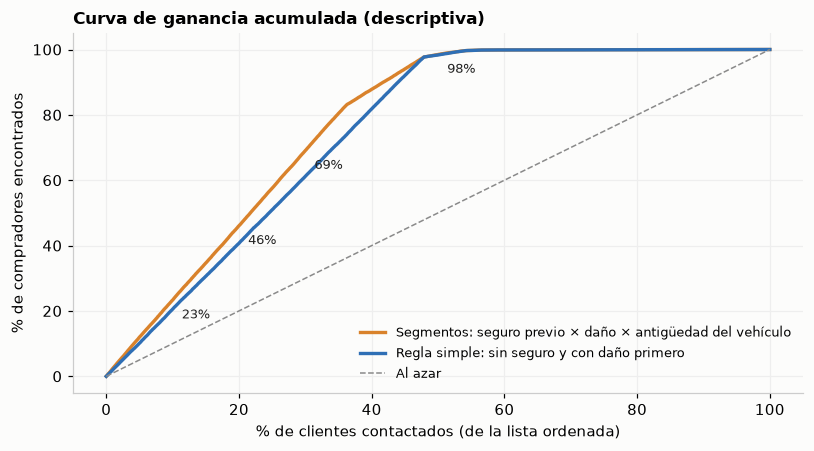

Llamando al 10% de la lista: segmentos encuentran 23.3% de los compradores; regla simple 20.6%; azar 10%.
Llamando al 20% de la lista: segmentos encuentran 46.1% de los compradores; regla simple 40.7%; azar 20%.
Llamando al 30% de la lista: segmentos encuentran 69.1% de los compradores; regla simple 61.2%; azar 30%.
Llamando al 50% de la lista: segmentos encuentran 98.5% de los compradores; regla simple 98.3%; azar 50%.


In [17]:
seg_key = ["Previously_Insured", "Vehicle_Damage", "Vehicle_Age"]
score = df.groupby(seg_key)[TARGET].transform("mean")

def gain_curve(s):
    order = np.argsort(-s.to_numpy(), kind="stable")
    cum = np.cumsum(y.to_numpy()[order]) / y.sum()
    return np.arange(1, len(s) + 1) / len(s), cum

fig, ax = plt.subplots(figsize=(7.5, 4.2))
x, c1 = gain_curve(score)
ax.plot(x * 100, c1 * 100, color=ORANGE, lw=2.2, label="Segmentos: seguro previo × daño × antigüedad del vehículo")
x, c2 = gain_curve((df.Vehicle_Damage == "Yes").astype(float) + 2 * (df.Previously_Insured == 0))
ax.plot(x * 100, c2 * 100, color=BLUE, lw=2.2, ls="-", label="Regla simple: sin seguro y con daño primero")
ax.plot([0, 100], [0, 100], color=GRAY, ls="--", lw=1, label="Al azar")
for p in (10, 20, 30, 50):
    i = int(len(df) * p / 100) - 1
    ax.annotate(f"{c1[i]:.0%}", (p, c1[i] * 100), textcoords="offset points", xytext=(6, -12), fontsize=8.5, color=INK)
ax.set_xlabel("% de clientes contactados (de la lista ordenada)")
ax.set_ylabel("% de compradores encontrados")
ax.set_title("Curva de ganancia acumulada (descriptiva)")
ax.legend(loc="lower right", fontsize=8.5, frameon=False)
plt.tight_layout()
plt.show()

for p in (10, 20, 30, 50):
    i = int(len(df) * p / 100) - 1
    print(f"Llamando al {p}% de la lista: segmentos encuentran {c1[i]:.1%} de los compradores; regla simple {c2[i]:.1%}; azar {p}%.")

**Insight 15 · Con solo tres variables se puede concentrar el 46 % de los compradores en el 20 % de la lista y el 98 % en la mitad.** La regla simple (sin seguro y con daño primero) se queda más abajo en el tramo inicial porque no
ordena dentro del grupo grande; ahí es donde la antigüedad del vehículo, la edad y el canal añaden orden. **Decisión de negocio:** si la capacidad de llamadas es limitada (por ejemplo el 20 % de los clientes), la prioridad la define el orden dentro del segmento clave,
no solo pertenecer a él. **[DECIDE EL GRUPO: ¿cuántas llamadas puede hacer el equipo comercial?]**

## 5. Insights para la toma de decisiones

| # | Qué muestran los datos | Decisión de **negocio** | Decisión de **datos / modelado** |
|---|---|---|---|
| 1 | Solo 12,26 % acepta (1 de cada 8) | Hay que priorizar; no llamar a todos | Partición estratificada; evaluar con PR-AUC y costo |
| 2 | Quien ya tiene seguro acepta 0,1 % (frente a 22,5 %) | Excluirlo de la lista: ahorra ≈ 46 % de los contactos | Conservar la variable; confirmar que no es fuga |
| 3 | Quien tuvo daño acepta 23,8 % (frente a 0,5 %) | Centrar la oferta en clientes con daño previo | Codificar Yes/No a 1/0 dentro del `Pipeline` |
| 4 | El segmento "sin seguro y con daño" tiene 48 % de los clientes y 97,7 % de los compradores | Es la lista base de llamadas; el modelo debe ordenar *dentro* de ella | Esa regla (costo 0,398 con R = 5) es la línea base que el modelo debe superar |
| 5 | Dentro de ese segmento, los menores de 26 años rinden 11,4 % y los de 26-55 rinden ≈ 29-32 % | No llamar a los menores de 26 con la misma oferta | La edad entra como tramos o con un modelo no lineal |
| 6 | Los canales 152 y 160 rinden 2-3 % y mueven 41 % de los clientes; los 26, 124 y 156 rinden 19-22 % | Revisar qué se vende y cómo en los canales 152 y 160 | Canal como categórica; agrupar los de pocos clientes y manejar canales nuevos de test |
| 7 | La región 28 reúne 28 % de los clientes y rinde 18,7 % | Es el mercado central; las regiones con tasa baja pueden no justificar campañas | Región como categórica |
| 8 | Prima, género, licencia y `Vintage` casi no aportan (0,4 % o menos) | No segmentar por prima ni por género | Medir el modelo con y sin `Vintage`; limitar extremos de prima; revisar equidad por género y edad |
| 9 | Hay 2 canales en test que no existen en train | — | Agrupar canales desconocidos en "otros" |

**Lo que estos datos NO dicen.** Son asociaciones: no prueban que el daño *cause* la compra ni que llamar a un cliente *produzca* la venta. Tampoco dicen nada del costo real de una llamada ni del margen de una venta (esos números dependen de la aseguradora; ver `R` en `01_caso_negocio.ipynb`).

## 6. Entregable de esta etapa

- [x] Este notebook ejecuta de principio a fin.
- [x] Unidad de análisis declarada: un cliente por fila (`id` único).
- [x] Más de 5 decisiones con cifra y motivo (secciones 3 a 5).
- [ ] Revisar las hipótesis marcadas **[DECIDE EL GRUPO]**.
- [ ] Copiar las decisiones aprobadas a `reports/01_eda.md` y `especificaciones/02-eda.md`.
- [ ] Alguien que **no** escribió el análisis sabe explicar por qué se tomó cada decisión.

**Siguiente:** `03_preprocesamiento.ipynb`.